# 🏦 Loan Approval Analysis & Exploratory Data Analysis (EDA)
**Dataset:** `loan_approval_analysis_400_rows_v2.csv`  
**Libraries:** `numpy`, `pandas`, `matplotlib`, `seaborn`  

This notebook performs complete exploratory data analysis, missing-value imputation, feature engineering (including all mentor-requested domain indicators), NumPy/Pandas statistical profiling, and multi-panel Seaborn/Matplotlib visualizations mirroring the 4-page Power BI dashboard.

## 1. Import Libraries & Load Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

# Load dataset
df = pd.read_csv(r"D:\#Cronus_Project\Raw_DataSet\loan_approval_analysis_400_rows_v2.csv")
print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()

Dataset Shape: 400 rows, 25 columns


,Application_ID,Application_Date,Age,Gender,Marital_Status,Dependents,Education,Employment_Type,Self_Employed,Applicant_Income_Monthly_INR,...,Existing_EMI_Monthly_INR,Monthly_Savings_INR,Debt_To_Income_Ratio,Loan_Amount_INR,Loan_Term_Months,Loan_Purpose,Property_Area,Collateral_Value_INR,Bank_Relationship_Years,Loan_Status
0,LA0001,2026-08-11,49,Female,Married,0.0,Graduate,Self-employed,Yes,61884,...,2653,15144,0.340,2495358,360,Home,Urban,2816386.0,9.4,Approved
1,LA0002,2025-03-03,33,Male,Single,3.0,Graduate,Salaried,No,15000,...,1855,1808,1.420,413966,24,Personal,Urban,0.0,4.0,Rejected
2,LA0003,2025-07-11,37,Male,Married,0.0,Graduate,Self-employed,Yes,77825,...,4525,8373,0.170,409626,60,Personal,Semiurban,NaN,15.2,Approved
3,LA0004,2025-05-19,55,Male,Single,0.0,Not Graduate,Salaried,No,59561,...,11074,13607,0.647,3007438,300,Home,Semiurban,1923954.0,13.0,Approved
4,LA0005,2025-03-04,21,Male,Single,3.0,Graduate,Self-employed,Yes,38972,...,5506,4131,0.469,605262,60,Vehicle,Rural,680691.0,1.3,Approved


## 2. Data Inspection, Duplicates & Missing Value Handling

In [2]:
# Check data types and non-null counts
print('--- Dataset Info ---')
df.info()

# Check duplicate rows
print(f'\nDuplicate Rows: {df.duplicated().sum()}')

# Check missing values
missing = df.isnull().sum()
print('\n--- Columns with Missing Values ---')
print(missing[missing > 0])

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Application_ID                  400 non-null    str    
 1   Application_Date                400 non-null    str    
 2   Age                             400 non-null    int64  
 3   Gender                          393 non-null    str    
 4   Marital_Status                  400 non-null    str    
 5   Dependents                      393 non-null    float64
 6   Education                       400 non-null    str    
 7   Employment_Type                 400 non-null    str    
 8   Self_Employed                   391 non-null    str    
 9   Applicant_Income_Monthly_INR    400 non-null    int64  
 10  Coapplicant_Income_Monthly_INR  400 non-null    int64  
 11  Household_Income_Monthly_INR    400 non-null    int64  
 12  Employment_Tenure_Years   

In [3]:
# Clean & Impute Missing Values
# Categorical / binary columns -> 'Unknown' or Mode
df['Gender'] = df['Gender'].fillna('Unknown')
df['Self_Employed'] = df['Self_Employed'].fillna(df['Self_Employed'].mode()[0])
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

# Numerical columns -> Median / 0 for missing collateral
df['Dependents'] = df['Dependents'].fillna(df['Dependents'].median())
df['Employment_Tenure_Years'] = df['Employment_Tenure_Years'].fillna(df['Employment_Tenure_Years'].median())
df['Collateral_Value_INR'] = df['Collateral_Value_INR'].fillna(0.0)

# Parse Application_Date

df['Application_Date'] = pd.to_datetime(df['Application_Date'], errors='coerce')
df['Application_Month'] = df['Application_Date'].dt.to_period('M').astype(str)

print('Total Missing Values After Cleaning:', df.isnull().sum().sum())

Total Missing Values After Cleaning: 0


## 3. Feature Engineering (Mentor-Requested Domain Indicators)
Deriving additional features using NumPy & Pandas:
- **`Loan_to_InHand_Cash_Ratio`**: Ratio of requested loan amount to net monthly in-hand savings (`Monthly_Savings_INR`).
- **`Residential_Status`**: Derived indicator (`Permanent` vs `Rented / Temporary`) based on collateral ownership and banking tenure.
- **`Vehicle_Status`**: Derived indicator (`Yes (Vehicle Linked)` vs `No / Unspecified`) from loan purpose and non-home collateral.
- **`Children_Dependents`**: Formatted string label for dependents.

In [4]:
# 1. Loan to In-Hand Cash Ratio (NumPy safe division)
df['Loan_to_InHand_Cash_Ratio'] = np.where(
    df['Monthly_Savings_INR'] > 0,
    df['Loan_Amount_INR'] / df['Monthly_Savings_INR'],
    0
)

# 2. Residential Status Proxy
df['Residential_Status'] = np.where(
    (df['Collateral_Value_INR'] > 0) | (df['Bank_Relationship_Years'] >= 5),
    'Permanent',
    'Rented / Temporary'
)

# 3. Vehicle Status Proxy
df['Vehicle_Status'] = np.where(
    (df['Loan_Purpose'] == 'Vehicle') | ((df['Loan_Purpose'] != 'Home') & (df['Collateral_Value_INR'] > 0)),
    'Yes (Vehicle Linked)',
    'No / Unspecified'
)

# 4. Children / Dependents Label
df['Children_Dependents'] = df['Dependents'].astype(int).astype(str) + ' Children'

df[['Application_ID', 'Loan_to_InHand_Cash_Ratio', 'Residential_Status', 'Vehicle_Status', 'Children_Dependents']].head()

,Application_ID,Loan_to_InHand_Cash_Ratio,Residential_Status,Vehicle_Status,Children_Dependents
0,LA0001,164.775357,Permanent,No / Unspecified,0 Children
1,LA0002,228.963496,Rented / Temporary,No / Unspecified,3 Children
2,LA0003,48.922250,Permanent,No / Unspecified,0 Children
3,LA0004,221.021386,Permanent,No / Unspecified,0 Children
4,LA0005,146.517066,Permanent,Yes (Vehicle Linked),3 Children


## 4. Statistical Summary with NumPy & Pandas

In [5]:
# Descriptive statistics for key numerical features
num_cols = [
    'Age', 'Household_Income_Monthly_INR', 'Employment_Tenure_Years',
    'Credit_Score', 'Existing_EMI_Monthly_INR', 'Monthly_Savings_INR',
    'Debt_To_Income_Ratio', 'Loan_Amount_INR', 'Collateral_Value_INR', 'Bank_Relationship_Years'
]
display(df[num_cols].describe().round(2))

# NumPy summary KPIs
approval_rate = np.mean(df['Loan_Status'] == 'Approved') * 100
median_loan = np.median(df['Loan_Amount_INR'])
p90_income = np.percentile(df['Household_Income_Monthly_INR'], 90)

print(f'Overall Approval Rate: {approval_rate:.2f}%')
print(f'Median Loan Amount: INR {median_loan:,.2f}')
print(f'90th Percentile Household Income: INR {p90_income:,.2f}')

,Age,Household_Income_Monthly_INR,Employment_Tenure_Years,Credit_Score,Existing_EMI_Monthly_INR,Monthly_Savings_INR,Debt_To_Income_Ratio,Loan_Amount_INR,Collateral_Value_INR,Bank_Relationship_Years
count,400.00,400.00,400.00,400.00,400.00,400.00,400.00,400.00,400.00,400.00
mean,41.91,74590.96,7.53,684.88,9555.18,10128.47,0.61,1670399.78,897844.51,8.23
std,11.90,47965.08,4.73,79.84,8954.49,8681.17,0.42,1295670.01,1285784.46,5.53
min,21.00,12000.00,0.20,453.00,438.00,403.00,0.09,117683.00,0.00,0.00
25%,32.00,40485.50,3.60,633.75,3682.50,4112.75,0.35,743963.75,0.00,3.40
50%,42.00,63695.50,6.50,686.50,6837.50,7844.50,0.50,1236159.00,162598.00,7.65
75%,52.00,92099.25,11.20,737.25,12286.25,13527.75,0.74,2172019.75,1425723.00,12.60
max,62.00,350000.00,18.00,850.00,70376.00,73547.00,3.41,6035762.00,6843123.00,19.80


Overall Approval Rate: 56.25%
Median Loan Amount: INR 1,236,159.00
90th Percentile Household Income: INR 135,490.60


## 5. Page 1 Visuals: Executive Summary & Overview

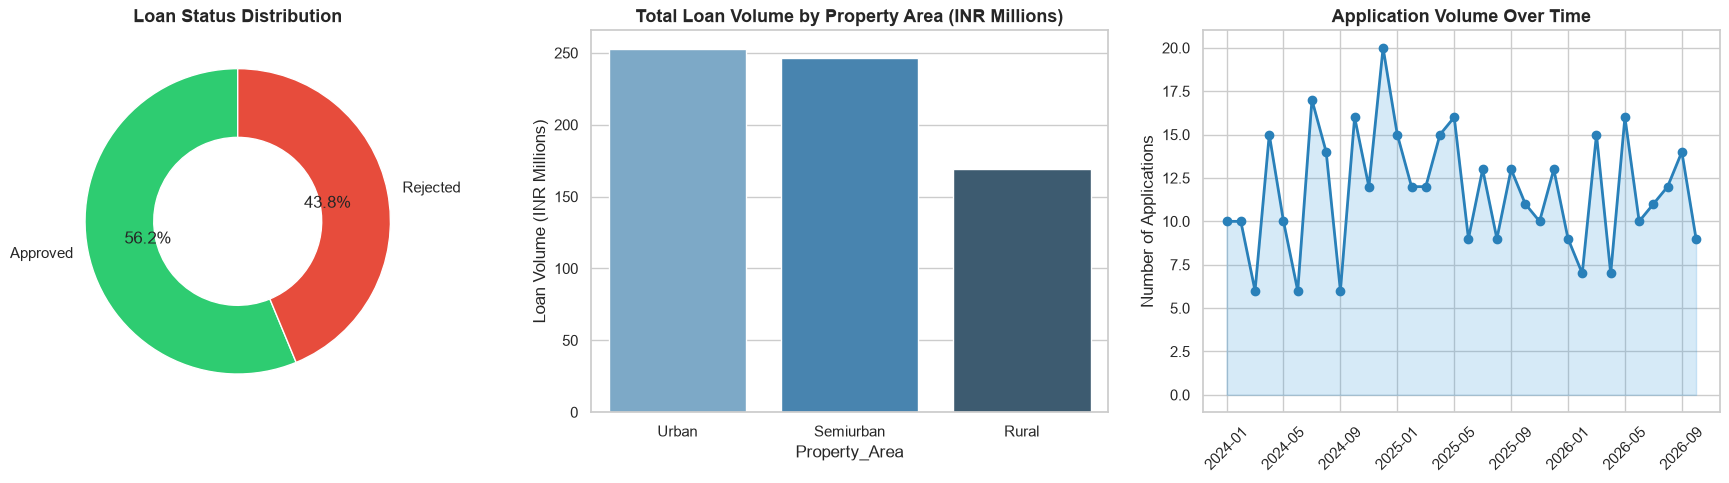

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loan Status Distribution (Donut Chart)
status_counts = df['Loan_Status'].value_counts()
axes[0].pie(
    status_counts, labels=status_counts.index, autopct='%1.1f%%',
    startangle=90, colors=['#2ecc71', '#e74c3c'], wedgeprops=dict(width=0.45)
)
axes[0].set_title('Loan Status Distribution')

# 2. Loan Volume by Property Area
area_vol = df.groupby('Property_Area')['Loan_Amount_INR'].sum().sort_values(ascending=False) / 1e6
sns.barplot(x=area_vol.index, y=area_vol.values, hue=area_vol.index, legend=False, ax=axes[1], palette='Blues_d')
axes[1].set_title('Total Loan Volume by Property Area (INR Millions)')
axes[1].set_ylabel('Loan Volume (INR Millions)')

# 3. Monthly Application Trend (Fixed numeric x-axis for fill_between)
monthly_trend = df[df['Application_Month'] != 'NaT'].groupby('Application_Month').size().sort_index()
x_pos = np.arange(len(monthly_trend))

axes[2].plot(x_pos, monthly_trend.values, marker='o', color='#2980b9', linewidth=2)
axes[2].fill_between(x_pos, monthly_trend.values, color='#3498db', alpha=0.2)
axes[2].set_title('Application Volume Over Time')
axes[2].set_ylabel('Number of Applications')

# Show every 3rd month label cleanly so they don't overlap
step = max(1, len(monthly_trend) // 8)
axes[2].set_xticks(x_pos[::step])
axes[2].set_xticklabels(monthly_trend.index[::step], rotation=45)

plt.tight_layout()
plt.show()

## 6. Page 2 Visuals: Credit Risk & Financial Health

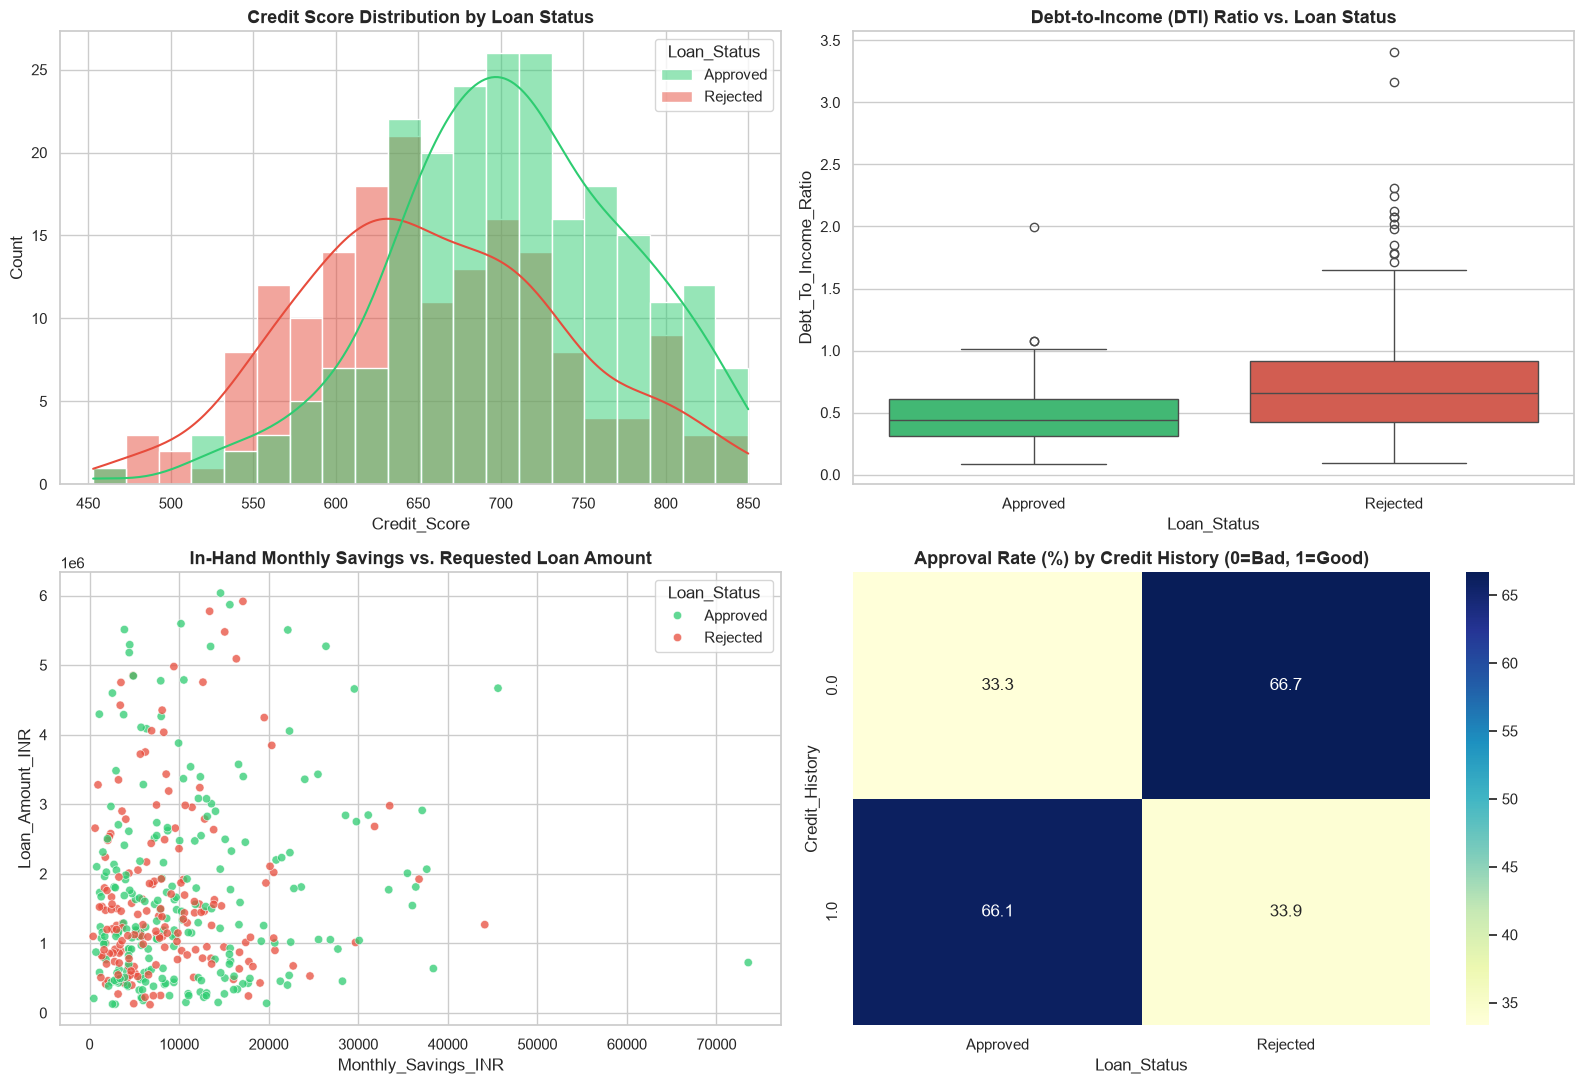

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Credit Score Distribution by Loan Status
sns.histplot(data=df, x='Credit_Score', hue='Loan_Status', kde=True, bins=20, ax=axes[0, 0], palette={'Approved': '#2ecc71', 'Rejected': '#e74c3c'})
axes[0, 0].set_title('Credit Score Distribution by Loan Status')

# 2. Debt-to-Income Ratio by Loan Status (Boxplot)
sns.boxplot(data=df, x='Loan_Status', y='Debt_To_Income_Ratio', hue='Loan_Status', legend=False, ax=axes[0, 1], palette={'Approved': '#2ecc71', 'Rejected': '#e74c3c'})
axes[0, 1].set_title('Debt-to-Income (DTI) Ratio vs. Loan Status')

# 3. Monthly In-Hand Savings vs. Loan Amount
sns.scatterplot(
    data=df, x='Monthly_Savings_INR', y='Loan_Amount_INR', hue='Loan_Status',
    alpha=0.75, ax=axes[1, 0], palette={'Approved': '#2ecc71', 'Rejected': '#e74c3c'}
)
axes[1, 0].set_title('In-Hand Monthly Savings vs. Requested Loan Amount')

# 4. Credit History Impact Crosstab Heatmap
ct_credit = pd.crosstab(df['Credit_History'], df['Loan_Status'], normalize='index') * 100
sns.heatmap(ct_credit, annot=True, fmt='.1f', cmap='YlGnBu', ax=axes[1, 1])
axes[1, 1].set_title('Approval Rate (%) by Credit History (0=Bad, 1=Good)')

plt.tight_layout()
plt.show()

## 7. Page 3 Visuals: Loan Purpose & Demographics

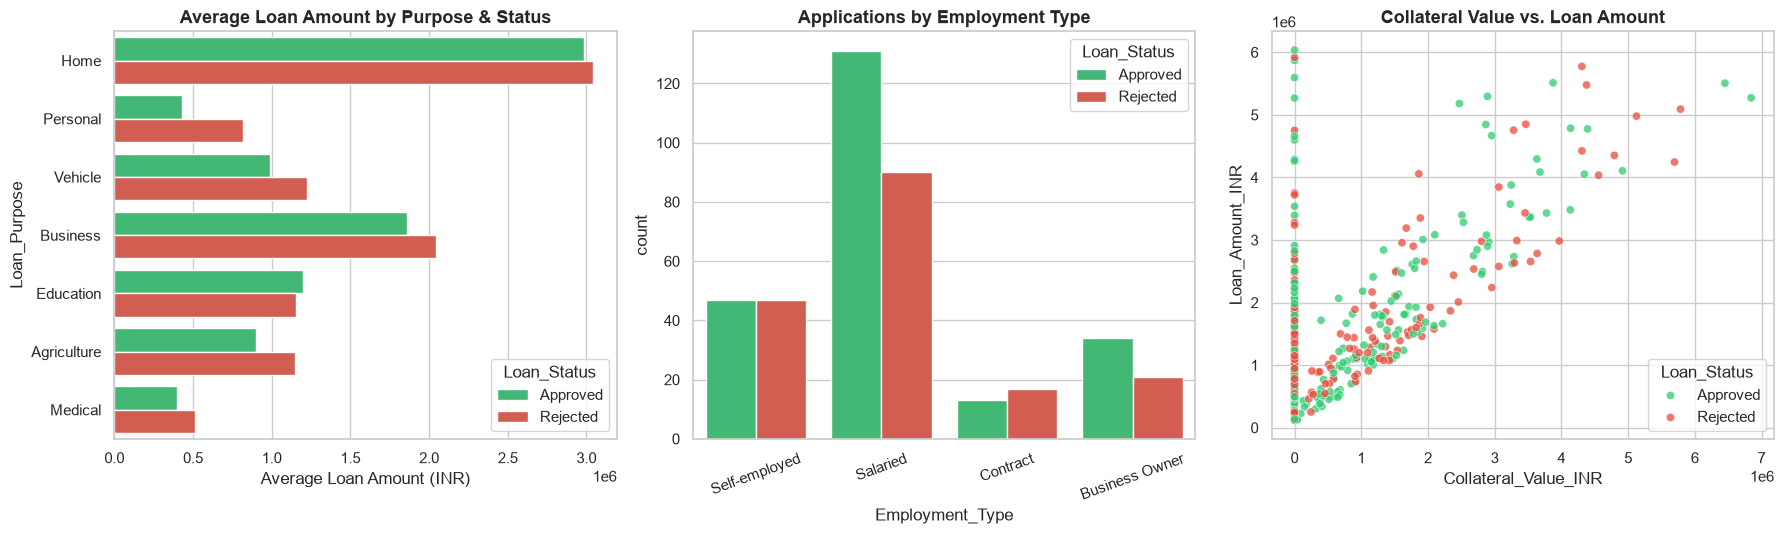

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Loan Amount by Purpose & Status
sns.barplot(
    data=df, y='Loan_Purpose', x='Loan_Amount_INR', hue='Loan_Status',
    estimator=np.mean, errorbar=None, ax=axes[0], palette={'Approved': '#2ecc71', 'Rejected': '#e74c3c'}
)
axes[0].set_title('Average Loan Amount by Purpose & Status')
axes[0].set_xlabel('Average Loan Amount (INR)')

# 2. Employment Type Breakdown
sns.countplot(data=df, x='Employment_Type', hue='Loan_Status', ax=axes[1], palette={'Approved': '#2ecc71', 'Rejected': '#e74c3c'})
axes[1].set_title('Applications by Employment Type')
axes[1].tick_params(axis='x', rotation=20)

# 3. Collateral Value vs. Loan Amount
sns.scatterplot(
    data=df, x='Collateral_Value_INR', y='Loan_Amount_INR', hue='Loan_Status',
    alpha=0.75, ax=axes[2], palette={'Approved': '#2ecc71', 'Rejected': '#e74c3c'}
)
axes[2].set_title('Collateral Value vs. Loan Amount')

plt.tight_layout()
plt.show()

## 8. Page 4 Visuals: Applicant Profile, Bank Loyalty & Mentor Indicators

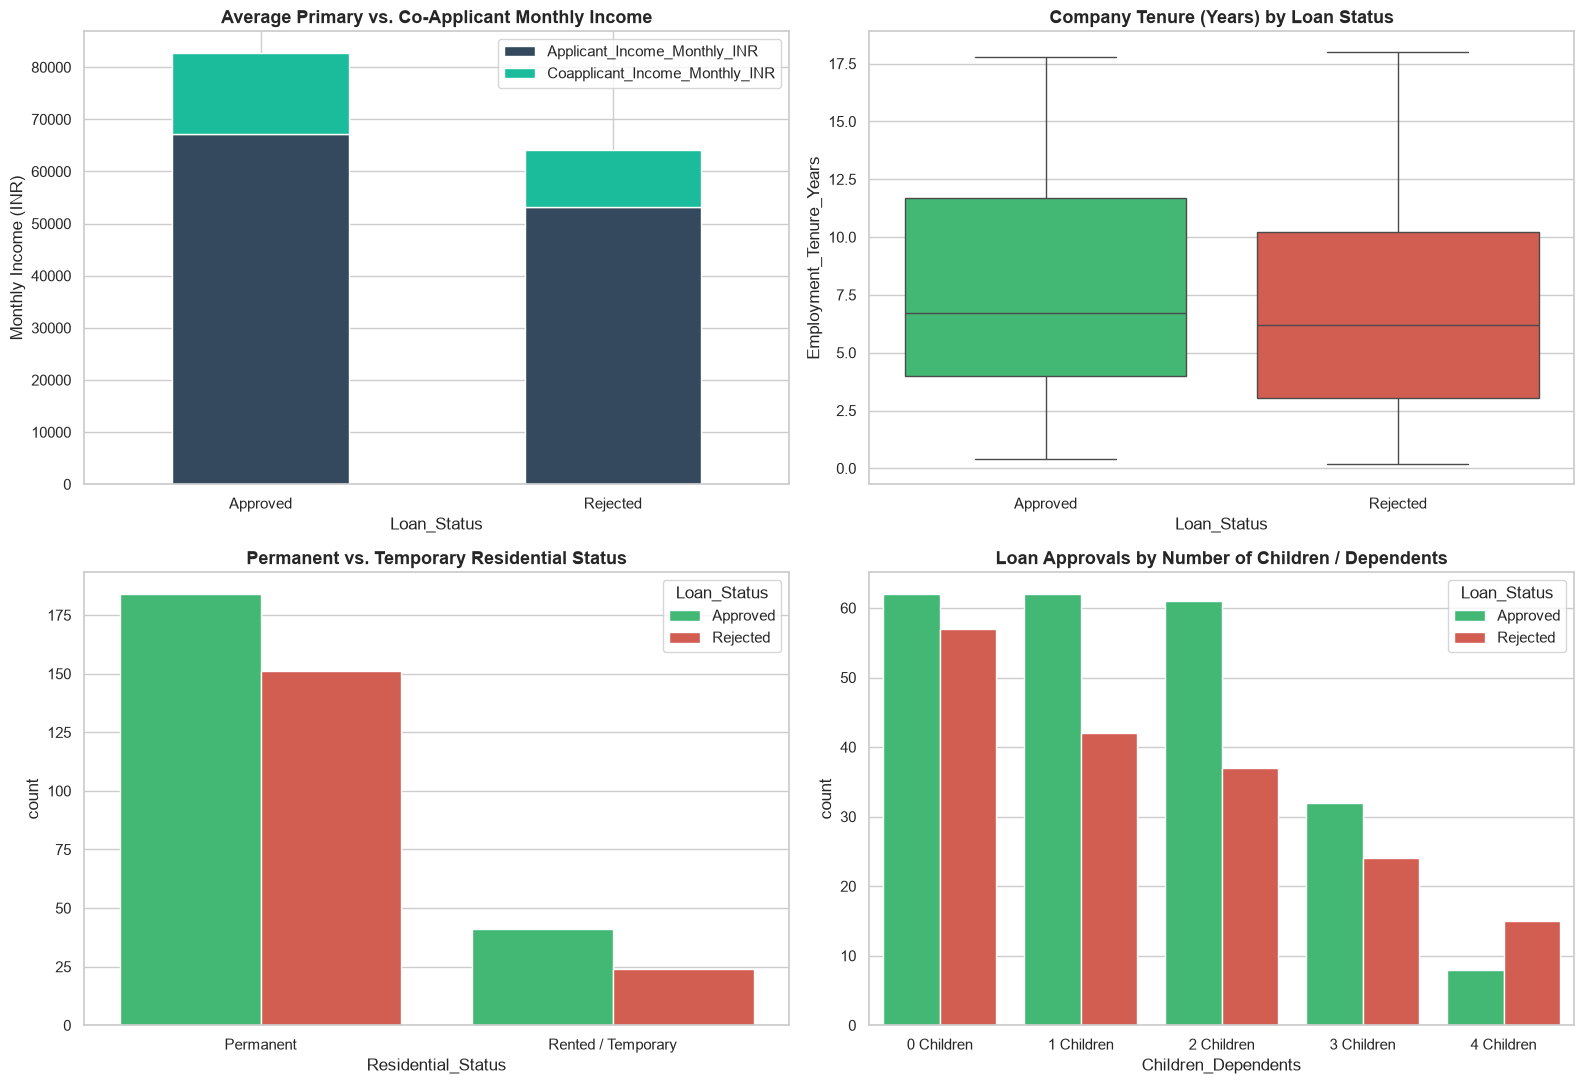

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Primary vs. Co-Applicant Income by Loan Status
income_split = df.groupby('Loan_Status')[['Applicant_Income_Monthly_INR', 'Coapplicant_Income_Monthly_INR']].mean()
income_split.plot(kind='bar', stacked=True, ax=axes[0, 0], color=['#34495e', '#1abc9c'])
axes[0, 0].set_title('Average Primary vs. Co-Applicant Monthly Income')
axes[0, 0].set_ylabel('Monthly Income (INR)')
axes[0, 0].tick_params(axis='x', rotation=0)

# 2. Employment Tenure (Last Company Staying) vs. Loan Status
sns.boxplot(data=df, x='Loan_Status', y='Employment_Tenure_Years', hue='Loan_Status', legend=False, ax=axes[0, 1], palette={'Approved': '#2ecc71', 'Rejected': '#e74c3c'})
axes[0, 1].set_title('Company Tenure (Years) by Loan Status')

# 3. Residential Status vs. Approval
sns.countplot(data=df, x='Residential_Status', hue='Loan_Status', ax=axes[1, 0], palette={'Approved': '#2ecc71', 'Rejected': '#e74c3c'})
axes[1, 0].set_title('Permanent vs. Temporary Residential Status')

# 4. Children / Dependents Overview
sns.countplot(
    data=df, x='Children_Dependents', hue='Loan_Status',
    order=['0 Children', '1 Children', '2 Children', '3 Children', '4 Children'],
    ax=axes[1, 1], palette={'Approved': '#2ecc71', 'Rejected': '#e74c3c'}
)
axes[1, 1].set_title('Loan Approvals by Number of Children / Dependents')

plt.tight_layout()
plt.show()

## 9. Correlation Heatmap Across Numerical Features

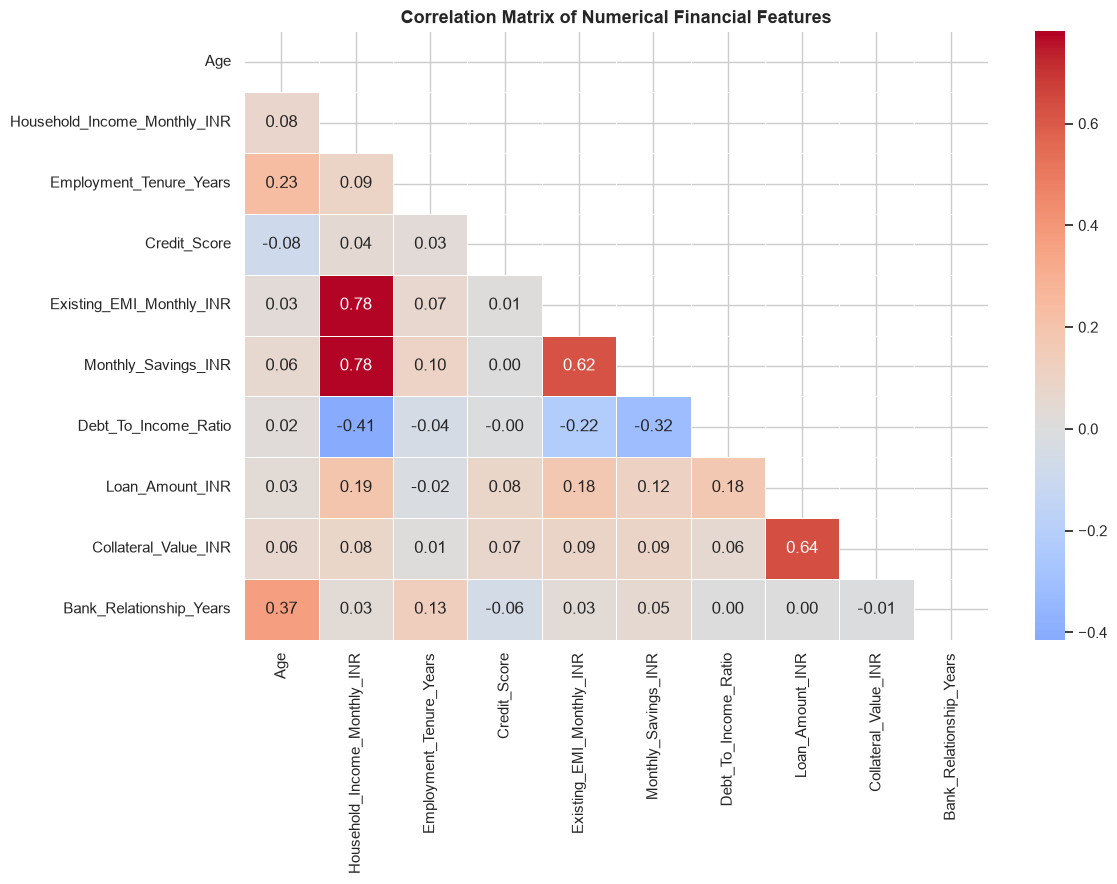

In [10]:
plt.figure(figsize=(12, 9))
corr_matrix = df[num_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Financial Features')
plt.tight_layout()
plt.show()